In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/online_retail_dataset_.csv", parse_dates=["InvoiceDate"])

print(df.shape)            # rows, columns
print(df.head())           # pehli 5 rows
print(df.info())           # data types
print(df.isnull().sum())   # missing values
print(df.describe())       # Quantity/UnitPrice ka summary

(14383, 8)
  InvoiceNo StockCode                       Description  Quantity  \
0    539856     22139   RETROSPOT TEA SET CERAMIC 11 PC         6   
1    539856     22632         HAND WARMER RED POLKA DOT         2   
2    539856     22178   VICTORIAN GLASS HANGING T-LIGHT         9   
3    537889     22178   VICTORIAN GLASS HANGING T-LIGHT         6   
4    540155     22720  SET OF 3 CAKE TINS PANTRY DESIGN         4   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 10:14:00       5.04     12865.0  United Kingdom  
1 2010-12-01 10:14:00       2.02     12865.0  United Kingdom  
2 2010-12-01 10:14:00       1.35     12865.0  United Kingdom  
3 2010-12-01 11:32:00       1.30     12581.0  United Kingdom  
4 2010-12-01 15:48:00       4.97     12909.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14383 entries, 0 to 14382
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----

In [3]:
# 1. Missing CustomerID removing
df = df.dropna(subset=["CustomerID"])

# 2. Cancelled orders removing
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# 3. Invalid Quantity / Price removing
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# 4. Duplicates removing
df = df.drop_duplicates()

# 5. CustomerID int float
df["CustomerID"] = df["CustomerID"].astype(int)

# 6. each row  total amount
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("After cleaning:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())

After cleaning: (13394, 9)
Unique customers: 600


In [4]:
# Snapshot date = dataset last date + 1 din (example "todays date")
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency   = ("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency = ("InvoiceNo", "nunique"),
    Monetary  = ("TotalPrice", "sum")
).reset_index()

print(rfm.head())
print(rfm.describe())

   CustomerID  Recency  Frequency  Monetary
0       12346      226          1    149.47
1       12347       71          1     54.70
2       12348      257          2    162.70
3       12349      144          4    237.60
4       12350        2         22   4480.20
         CustomerID     Recency   Frequency     Monetary
count    600.000000  600.000000  600.000000   600.000000
mean   12645.500000  119.013333    6.435000   804.424333
std      173.349358  113.710686    6.341356  1293.727979
min    12346.000000    1.000000    1.000000     1.790000
25%    12495.750000   17.000000    2.000000   107.470000
50%    12645.500000   67.000000    5.000000   305.950000
75%    12795.250000  216.000000    8.000000   597.637500
max    12945.000000  373.000000   29.000000  6041.760000


In [5]:

rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm["RFM_Total"] = rfm[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

print(rfm.head(10))
print(rfm.sort_values("RFM_Total", ascending=False).head())   # top customers

   CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0       12346      226          1    149.47        2        1        2   
1       12347       71          1     54.70        3        1        1   
2       12348      257          2    162.70        1        2        2   
3       12349      144          4    237.60        3        2        3   
4       12350        2         22   4480.20        5        5        5   
5       12351       17          6   3594.96        4        3        5   
6       12352      233          2    306.06        2        2        3   
7       12353      268          2    158.09        1        2        2   
8       12354       36          9    304.73        4        4        3   
9       12355       26          2     16.43        4        2        1   

  RFM_Score  RFM_Total  
0       212          5  
1       311          5  
2       122          5  
3       323          8  
4       555         15  
5       435         12  
6       22

In [6]:
def rule_segment(r):
    if r.R_Score >= 4 and r.F_Score >= 4:
        return "Champions"
    if r.R_Score >= 3 and r.F_Score >= 3:
        return "Loyal Customers"
    if r.R_Score >= 4 and r.F_Score <= 2:
        return "New / Promising"
    if r.R_Score <= 2 and r.F_Score >= 3:
        return "At-Risk"
    if r.R_Score <= 2 and r.F_Score <= 2 and r.M_Score <= 2:
        return "Lost"
    return "Need Attention"

rfm["Segment_Rule"] = rfm.apply(rule_segment, axis=1)


print(rfm["Segment_Rule"].value_counts())

print(rfm.groupby("Segment_Rule")[["Recency", "Frequency", "Monetary"]].mean().round(1))

Segment_Rule
Champions          155
Lost               129
Loyal Customers    106
At-Risk             99
New / Promising     61
Need Attention      50
Name: count, dtype: int64
                 Recency  Frequency  Monetary
Segment_Rule                                 
At-Risk            185.6        6.0     366.4
Champions           12.3       14.4    2152.6
Lost               288.7        1.5      81.8
Loyal Customers     71.2        6.3     766.4
Need Attention     104.4        1.7     260.3
New / Promising     18.6        1.6     129.9


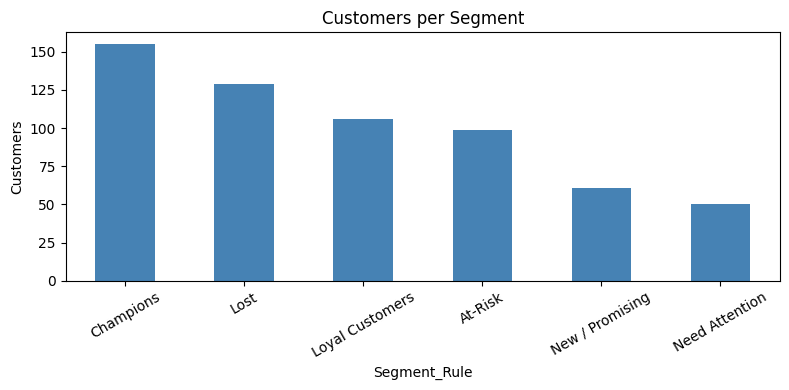

In [7]:
rfm["Segment_Rule"].value_counts().plot(kind="bar", color="steelblue", figsize=(8, 4))
plt.title("Customers per Segment")
plt.ylabel("Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = rfm[["Recency", "Frequency", "Monetary"]].copy()

X_log = np.log1p(X)

X_scaled = StandardScaler().fit_transform(X_log)

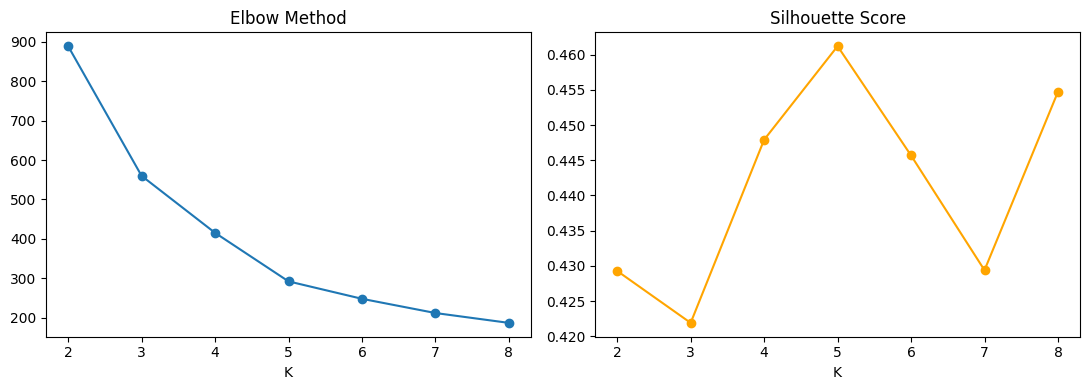

In [9]:
inertia, sil = [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(K_range, inertia, "o-")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("K")
ax[1].plot(K_range, sil, "o-", color="orange")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("K")
plt.tight_layout()
plt.show()

In [10]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

In [11]:
profile = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1)
profile["Customers"] = rfm["Cluster"].value_counts()
print(profile)

         Recency  Frequency  Monetary  Customers
Cluster                                         
0          116.9        6.4     538.3        241
1            7.5       15.1    2539.1        131
2           32.7        1.4      85.5         92
3          288.6        1.5      91.5        136


In [12]:
remaining = set(profile.index)

champ = profile["Monetary"].idxmax()
remaining.discard(champ)

lost = profile.loc[list(remaining), "Recency"].idxmax()
remaining.discard(lost)

new = profile.loc[list(remaining), "Frequency"].idxmin()
remaining.discard(new)

cluster_map = {champ: "Champions", lost: "Lost", new: "New Customers"}
for c in remaining:
    cluster_map[c] = "At-Risk"

rfm["Segment"] = rfm["Cluster"].map(cluster_map)
print(rfm["Segment"].value_counts())

Segment
At-Risk          241
Lost             136
Champions        131
New Customers     92
Name: count, dtype: int64


In [13]:
palette = {
    "Champions": "#2ca02c",      # green
    "New Customers": "#1f77b4",  # blue
    "At-Risk": "#ff7f0e",        # orange
    "Lost": "#d62728"            # red
}

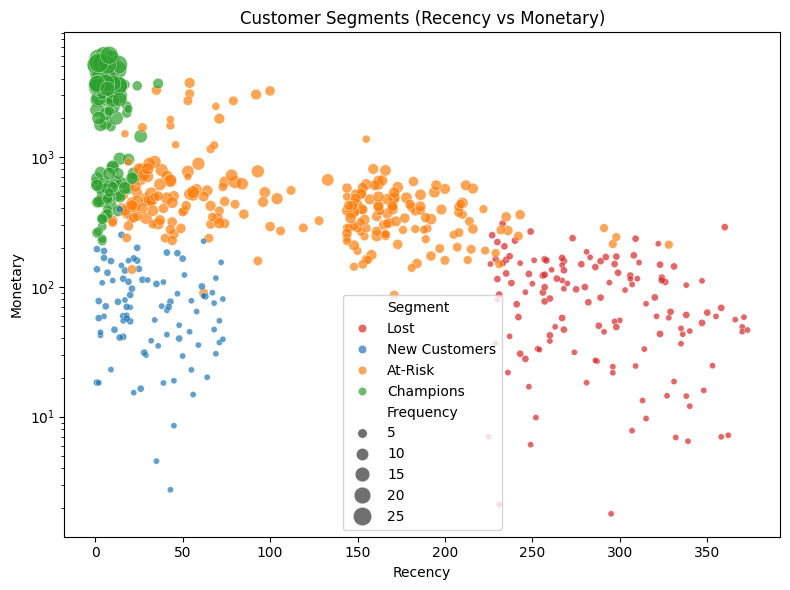

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment",
                size="Frequency", palette=palette, alpha=0.7, sizes=(20, 200))
plt.yscale("log")
plt.title("Customer Segments (Recency vs Monetary)")
plt.tight_layout()
plt.savefig("segments_scatter.png", dpi=150)
plt.show()

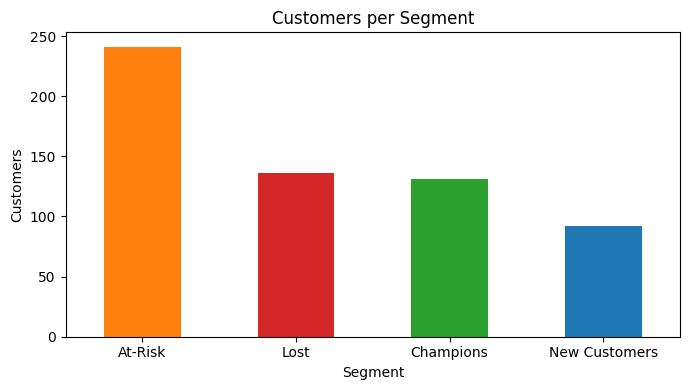

In [15]:
counts = rfm["Segment"].value_counts()
plt.figure(figsize=(7, 4))
counts.plot(kind="bar", color=[palette[s] for s in counts.index])
plt.title("Customers per Segment")
plt.ylabel("Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("segment_sizes.png", dpi=150)
plt.show()

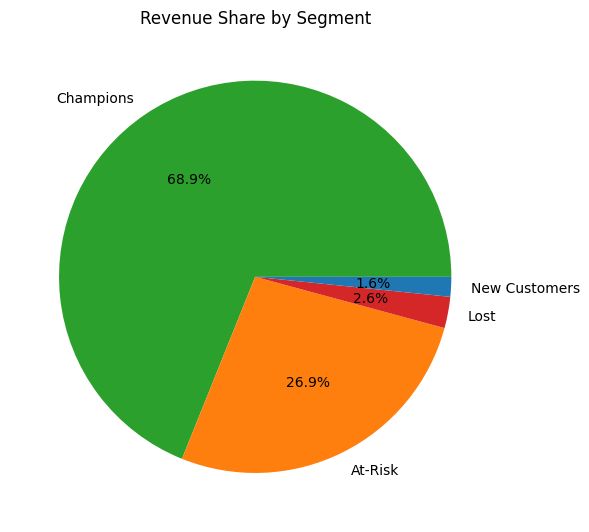

In [16]:
rev = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 6))
plt.pie(rev, labels=rev.index, autopct="%1.1f%%",
        colors=[palette[s] for s in rev.index])
plt.title("Revenue Share by Segment")
plt.tight_layout()
plt.savefig("revenue_share.png", dpi=150)
plt.show()

In [18]:
summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(1)

summary["Revenue_%"] = (summary["Total_Revenue"] / summary["Total_Revenue"].sum() * 100).round(1)
print(summary)


rfm.drop(columns=["Cluster"]).to_csv("rfm_scores.csv", index=False)
summary.to_csv("segment_summary.csv")
print("Done!")

               Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Segment                                                              
At-Risk              241        116.9            6.4         538.3   
Champions            131          7.5           15.1        2539.1   
Lost                 136        288.6            1.5          91.5   
New Customers         92         32.7            1.4          85.5   

               Total_Revenue  Revenue_%  
Segment                                  
At-Risk             129721.7       26.9  
Champions           332625.2       68.9  
Lost                 12445.5        2.6  
New Customers         7862.1        1.6  
Done!
